In [1]:
print("Importing----")

import os, sys, time, subprocess, tempfile
from coffea import processor
import coffea.util
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()
%matplotlib inline
import mplhep as hep


Importing----


In [2]:



bgs= [
       "DYJetsToLL_M50",
     
]

In [3]:
print("========Runner=======")

runner = processor.Runner(
    executor=processor.IterativeExecutor(),
    # executor=processor.FuturesExecutor(),
    # executor=processor.DaskExecutor(client=client),
    schema = llpnanoaodschema.LLPNanoAODSchema,
    skipbadfiles=True,
    
)
channel_name = "cr_Zmumu" #"cr_Zmumu_muon_hits"
hist_collection = "test"
print("=======Processor=========")

p = sidm_processor.SidmProcessor([channel_name,  ], [hist_collection])

========Runner=======
=======Processor=========


In [4]:
print(p)

In [5]:
print("========Fileset========")
max_files_bg = 1
max_files_data =1
max_files_signal = 1

# fileset = utilities.make_fileset([data[0]], "llpNanoAOD_v2",
#              max_files=max_files_data,location_cfg="data_skimmed.yaml")
# output = runner.run(fileset, treename="Events", processor_instance=p)

# fileset = utilities.make_fileset(signals_all[0], "llpNanoAOD_v2", max_files=max_files_signal, location_cfg="signal_4mu_v10.yaml")
# output= runner.run(fileset, treename="Events", processor_instance=p)

fileset = utilities.make_fileset(bgs, "skimmed_llpNanoAOD_v2", location_cfg="backgrounds.yaml", max_files=max_files_bg)
output = runner.run(fileset, treename="Events", processor_instance=p)




========Fileset========


Output()

Output()

/usr/local/lib/python3.12/site-packages/coffea/nanoevents/schemas/nanoaod.py:264: RuntimeWarning: Missing 
cross-reference index for LowPtElectron_electronIdx => Electron
  warnings.warn(

/usr/local/lib/python3.12/site-packages/coffea/nanoevents/schemas/nanoaod.py:264: RuntimeWarning: Missing 
cross-reference index for LowPtElectron_photonIdx => Photon
  warnings.warn(

/usr/local/lib/python3.12/site-packages/awkward/_nplikes/array_module.py:289: RuntimeWarning: invalid value 
encountered in divide
  return impl(*broadcasted_args, **(kwargs or {}))

Warning: Unable to apply all for nested dsaMuons collection. Skipping.... no field named 'good_matched_muons'

DYJetsToLL_M50 is simulation. Scaling histograms or cutflows according to lumi*xs.


In [13]:
print(output["out"]["DYJetsToLL_M50"]["metadata"]["objs"].keys())

dict_keys(['pvs', 'bs', 'met', 'hlt', 'electrons', 'photons', 'muons', 'dsaMuons', 'weight', 'gens', 'genMus', 'genEs', 'genAs', 'genAs_toMu', 'genAs_toE', 'rho_PFIso', 'jets', 'flags', 'bjets', 'ljs', 'mu_ljs', 'egm_ljs', 'pfmu_ljs', 'dsamu_ljs', 'electron_ljs', 'photon_ljs', 'allMuons', 'genMus_fromA', 'genEs_fromA', 'evt_weights', 'ch', 'lj_reco'])


In [14]:
objs=output["out"]["DYJetsToLL_M50"]["metadata"]["objs"]

In [24]:
muons = objs["muons"]
weights = objs["evt_weights"]



In [25]:
print(len(objs["muons"]))



69


In [28]:
for x in range(69):
    print(muons[x].pt, weights[x])

[30.4, 29.7] 1.0
[50.7, 28.5] 1.0
[71.3, 29.9] 1.0
[41.7, 26.7] 1.0
[30.5, 27.1] 1.0
[58.7, 29.1] 1.0
[43.1, 28.8] 1.0
[43.1, 28.4] 1.0
[70.8, 27.7] 1.0
[41.4, 26.3] 1.0
[53.7, 26.7] 1.0
[27.8, 26.9] 1.0
[32.9, 29.8] 1.0
[35, 28.1] 1.0
[53.2, 27.9] 1.0
[86.4, 28.7] 1.0
[40.2, 26.7] 1.0
[30.9, 26.5] 1.0
[81.8, 26.5] 1.0
[37.9, 28.8] 1.0
[34.1, 27.1] 1.0
[68.9, 29] 1.0
[43.4, 28.2] 1.0
[35.8, 28.8] 1.0
[33, 27] 1.0
[35.4, 28] 1.0
[46.3, 27] 1.0
[29.8, 27.4] 1.0
[28.4, 27.7] 1.0
[45.9, 29.9] 1.0
[48.2, 30] 1.0
[75.7, 26.7] 1.0
[46.8, 29.5] 1.0
[43.3, 26.6] 1.0
[80.2, 27.4] 1.0
[34.1, 29] 1.0
[51.4, 27.4] 1.0
[27.1, 26.8] 1.0
[36.4, 29.2] 1.0
[37.8, 26.8] 1.0
[64.3, 30] 1.0
[29.5, 27.7] 1.0
[27.6, 26.2] 1.0
[36.8, 28.9] 1.0
[39.3, 29.6] 1.0
[45.8, 27.6] 1.0
[27.2, 26.4, 8.97] 1.0
[48.4, 29.6] 1.0
[46.4, 29.1] 1.0
[47.4, 29.3] 1.0
[58.2, 28.8] 1.0
[94.1, 27.2] 1.0
[67.3, 29.8] 1.0
[64.2, 29.7] 1.0
[31.2, 27.4] 1.0
[47.8, 29.6] 1.0
[42.3, 29.2] 1.0
[40.1, 29.2] 1.0
[59.2, 26.8] 1.0
[38.8, 27

In [6]:
print(output["out"]["DYJetsToLL_M50"]["hists"].keys())

dict_keys(['mu0_mu1_dR_vs_jet0_mu0_dR', 'mu0_mu1_dR_vs_jet0_mu1_dR'])


=======Plotting=======
37266.78515625


<Figure size 500x500 with 0 Axes>

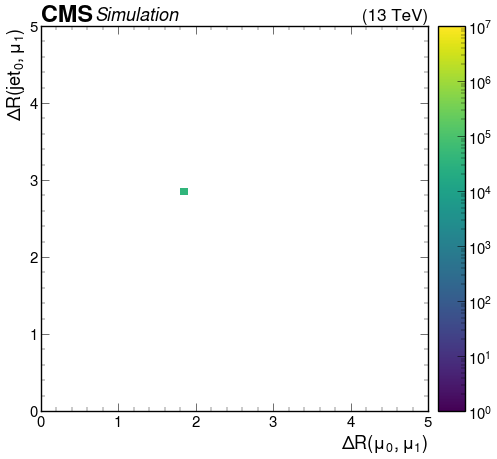

<Figure size 500x500 with 0 Axes>

In [22]:
from matplotlib.colors import LogNorm

print("=======Plotting=======")

histogram1 = output["out"][bgs[0]]["hists"]["mu0_mu1_dR_vs_jet0_mu1_dR"][channel_name, :, :]
print(histogram1.values().sum())

utilities.plot(histogram1, norm=LogNorm(1, 1e7))

plt.figure()

In [8]:
from matplotlib.colors import LogNorm

print("=======Plotting=======")

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_leading_vs_dR"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

plt.figure()

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_subleading_vs_dR"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

print("=======Plotting=======")
plt.figure()

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_leading_vs_dR_event_mask"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

plt.figure()

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_subleading_vs_dR_event_mask"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

=======Plotting=======


KeyError: 'muon_dthits_plus_cschits_leading_vs_dR'

In [ ]:
print("=======Plotting=======")
# histogram1 = output["out"][S[0]]["hists"]["muon_dz_innerVz_diff"][channelname,:]
# histogram1 = output["out"][data[0]]["hists"]["muon_dthits_plus_cschits"][channel_name,:]
histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits"][channel_name,:]
plt.yscale("log")

utilities.plot(histogram1, yerr=False)
